In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load the cleaned dataset

df = pd.read_excel("../Dataset/Cleaned/weather_2026_5_cities_cleaned.xlsx")

In [3]:
# Prepare the date column

df["time"] = pd.to_datetime(df["time"])

df["month"] = df["time"].dt.month

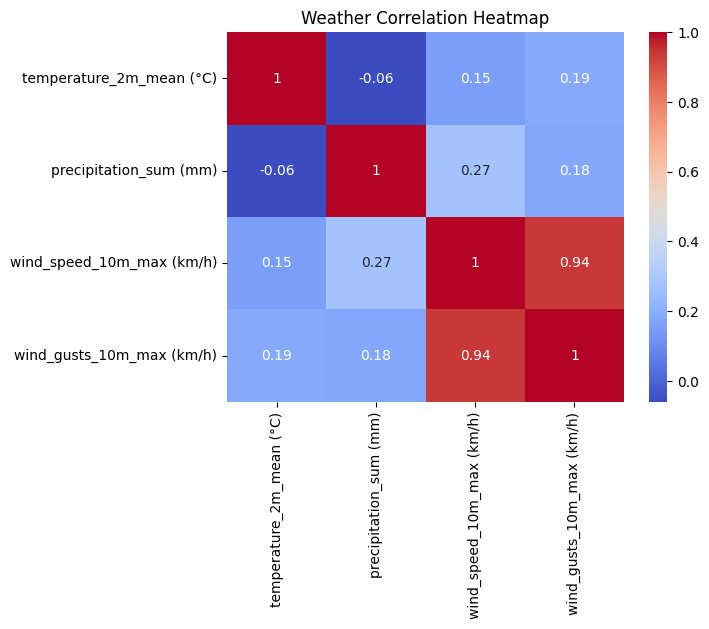

In [4]:
# Which weather variables have the strongest correlation?

corr = df[[
    "temperature_2m_mean (°C)",
    "precipitation_sum (mm)",
    "wind_speed_10m_max (km/h)",
    "wind_gusts_10m_max (km/h)"
]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Weather Correlation Heatmap")
plt.show()

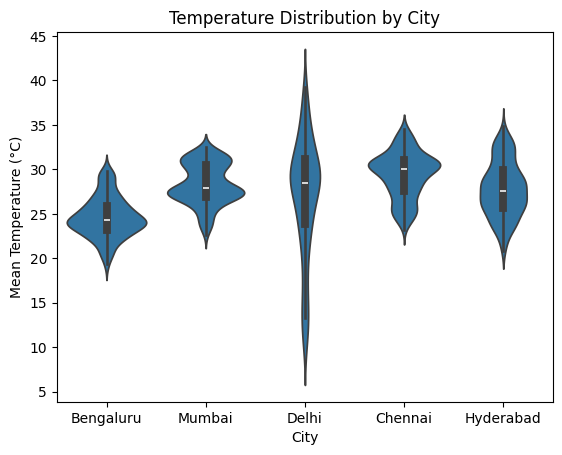

In [5]:
# How does the temperature distribution differ across the five cities?

sns.violinplot(
    data=df,
    x="city",
    y="temperature_2m_mean (°C)"
)

plt.title("Temperature Distribution by City")
plt.xlabel("City")
plt.ylabel("Mean Temperature (°C)")
plt.show()

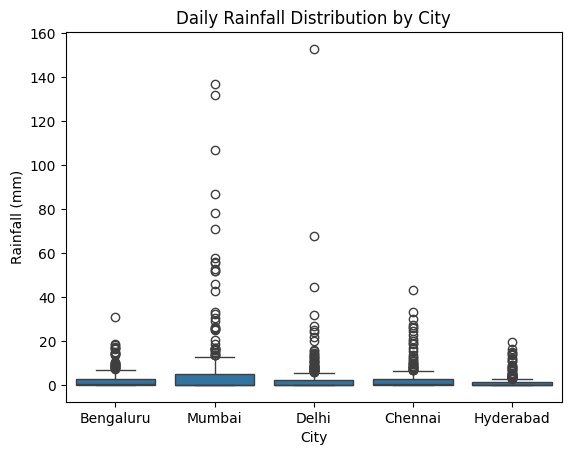

In [6]:
# Which city has the highest variation in daily rainfall?

sns.boxplot(
    data=df,
    x="city",
    y="precipitation_sum (mm)"
)

plt.title("Daily Rainfall Distribution by City")
plt.xlabel("City")
plt.ylabel("Rainfall (mm)")
plt.show()

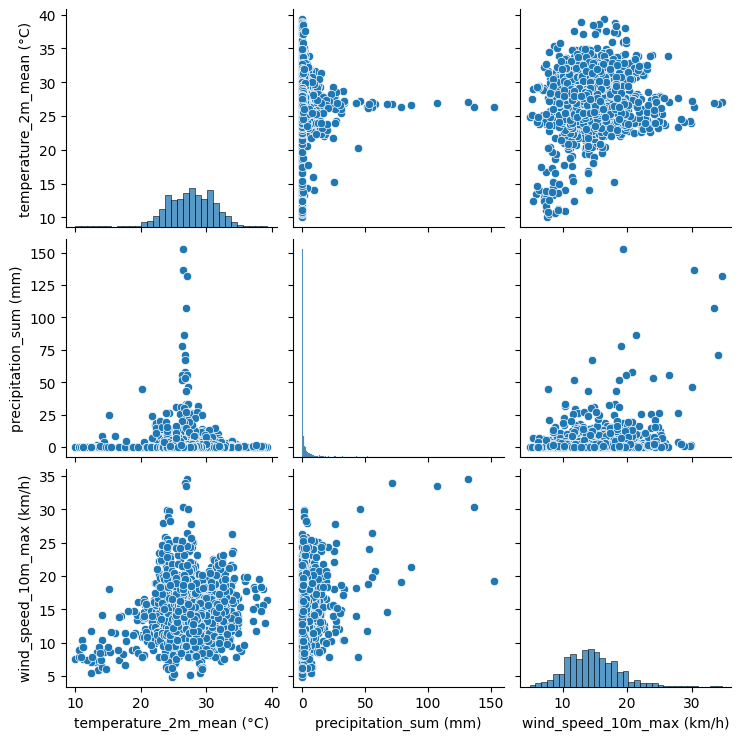

In [7]:
# What relationships exist between temperature, rainfall and wind speed across the five cities?

weather_data = df[[
    "temperature_2m_mean (°C)",
    "precipitation_sum (mm)",
    "wind_speed_10m_max (km/h)"
]]

sns.pairplot(weather_data)

plt.show()

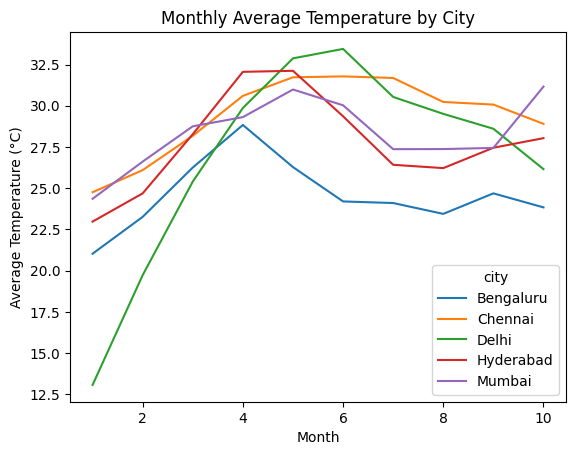

In [9]:
# How do monthly average temperatures compare across all five cities?

monthly_temp = df.groupby(
    ["city", "month"]
)["temperature_2m_mean (°C)"].mean().reset_index()

sns.lineplot(
    data=monthly_temp,
    x="month",
    y="temperature_2m_mean (°C)",
    hue="city"
)

plt.title("Monthly Average Temperature by City")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.show()
